# Week 7 - Clipping

In this lesson we will learn how to clip different geometries.

By the end of this lesson, you will be able to:

- reproject geo-dataframes so they share the same CRS 
- clip a `geopandas.GeoDataFrame` to the polygons of another one using `geopandas.clip()`
- subset tabular data before applying geospatial operations
- decide when to clip to a bounding box instead of the exact polygons

## About the data

We will use three datasets. Put each unzipped folder inside a `data/` folder at the same level as this notebook.

1. **US states**: the 2026 [TIGER shapefile of the US states](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html#form-dropdown-790442341) from the United States Census Bureau. You already have this dataset in your computer. 

2. **Populated places**: [Natural Earth's medium-scale populated places dataset (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). Under "Populated Places", download the simple version (the one that says "simple (less columns)"). You will get a `ne_50m_populated_places_simple` folder.

3. **Roads**: [Natural Earth's large-scale roads dataset (1:10m)](https://www.naturalearthdata.com/downloads/10m-cultural-vectors/roads/). Download the shapefile. You will get a `ne_10m_roads` folder.

Read the [lesson's "About the data" section](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-13-clipping/lesson-13-clipping.html#about-the-data) for more information about the datasets, including the column descriptions of the US states shapefile.

## Import data

Let's start by loading our libraries and then importing the datasets we will use.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from shapely.geometry import box  # To create polygon bounding box


pd.set_option("display.max.columns", None)

# -------------------------------------------------------
# === MODIFY AS NEEDED TO IMPORT YOUR DATA ===

# Import states polygons
states = gpd.read_file(os.path.join('data', 
                                    'tl_2026_us_state', 
                                    'tl_2026_us_state.shp'))

# Import Natural Earth populated places points
places = gpd.read_file(os.path.join('data',
                                    'ne_50m_populated_places_simple',
                                    'ne_50m_populated_places_simple.shp')
                                    )

# Import roads lines
roads = gpd.read_file(os.path.join('data',
                                   'ne_10m_roads',
                                   'ne_10m_roads.shp')
                                   )

## Check-in (complete before class)
Use a `for` loop to iterate over the three geo-dataframes we imported and change their column names to lowercase.

In [2]:
# Change all column names in all datasets to lower case

# Create list of df
datasets = [states,places,roads]

# Iterate through dfs in list
for ds in datasets:
    # Change column names to lowercase
    ds.columns = ds.columns.str.lower()
    # Print column names to confirm
    print(ds.columns)


Index(['region', 'division', 'statefp', 'statens', 'geoid', 'geoidfq',
       'stusps', 'name', 'lsad', 'mtfcc', 'funcstat', 'aland', 'awater',
       'intptlat', 'intptlon', 'geometry'],
      dtype='object')
Index(['scalerank', 'natscale', 'labelrank', 'featurecla', 'name', 'namepar',
       'namealt', 'nameascii', 'adm0cap', 'capalt', 'capin', 'worldcity',
       'megacity', 'sov0name', 'sov_a3', 'adm0name', 'adm0_a3', 'adm1name',
       'iso_a2', 'note', 'latitude', 'longitude', 'pop_max', 'pop_min',
       'pop_other', 'rank_max', 'rank_min', 'meganame', 'ls_name', 'min_zoom',
       'ne_id', 'geometry'],
      dtype='object')
Index(['scalerank', 'featurecla', 'type', 'sov_a3', 'note', 'edited', 'name',
       'namealt', 'namealtt', 'routeraw', 'question', 'length_km', 'toll',
       'ne_part', 'label', 'label2', 'local', 'localtype', 'localalt',
       'labelrank', 'ignore', 'add', 'rwdb_rd_id', 'orig_fid', 'prefix',
       'uident', 'continent', 'expressway', 'level', 'min_zoom'

## Prepare Alaska multipolygon

In [3]:
# Check crs
print(f"CRS: {states.crs}")

# Print df head
states.head(3)

CRS: EPSG:4269


,region,division,statefp,statens,geoid,geoidfq,stusps,name,lsad,mtfcc,funcstat,aland,awater,intptlat,intptlon,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


<Axes: >

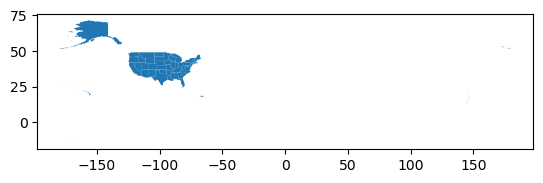

In [6]:
states.plot()

<Axes: >

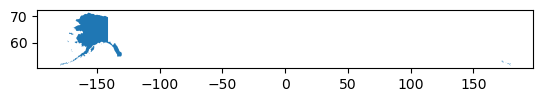

In [7]:
alaska = states[states['name'] == 'Alaska']
alaska.plot()

In [8]:
# Reproject to CRS optimized for Alaska
alaska = alaska.to_crs('epsg:3338')

# Inspect the new CRS
print('Is this CRS projected? ', alaska.crs.is_projected)
alaska.crs

Is this CRS projected?  True


<Projected CRS: EPSG:3338>
Name: NAD83 / Alaska Albers
Axis Info [cartesian]:
- X[east]: Easting (metre)
- Y[north]: Northing (metre)
Area of Use:
- name: United States (USA) - Alaska.
- bounds: (172.42, 51.3, -129.99, 71.4)
Coordinate Operation:
- name: Alaska Albers (meter)
- method: Albers Equal Area
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

<Axes: >

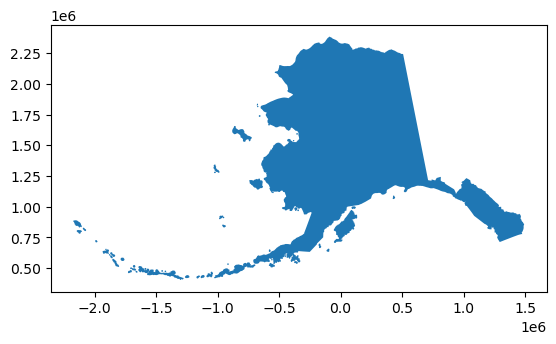

In [ ]:
# Plot data w/ new crs
alaska.plot()

## Prepare populated places points

In [ ]:
# Check crs
print(f"CRS: {places.crs}")

# Print df head
places.head(3)

CRS: EPSG:4326


,scalerank,natscale,labelrank,featurecla,name,namepar,namealt,nameascii,adm0cap,capalt,capin,worldcity,megacity,sov0name,sov_a3,adm0name,adm0_a3,adm1name,iso_a2,note,latitude,longitude,pop_max,pop_min,pop_other,rank_max,rank_min,meganame,ls_name,min_zoom,ne_id,geometry
0,10,1,5,Admin-1 region capital,Bombo,None,None,Bombo,0,0,None,0,0,Uganda,UGA,Uganda,UGA,Bamunanika,UG,None,0.583299,32.533300,75000,21000,0.0,8,7,None,None,7.0,1159113923,POINT (32.53330 0.58330)
1,10,1,5,Admin-1 region capital,Fort Portal,None,None,Fort Portal,0,0,None,0,0,Uganda,UGA,Uganda,UGA,Kabarole,UG,None,0.671004,30.275002,42670,42670,0.0,7,7,None,None,7.0,1159113959,POINT (30.27500 0.67100)
2,10,1,3,Admin-1 region capital,Potenza,None,None,Potenza,0,0,None,0,0,Italy,ITA,Italy,ITA,Basilicata,IT,None,40.642002,15.798997,69060,69060,0.0,8,8,None,None,7.0,1159117259,POINT (15.79900 40.64200)


<Axes: >

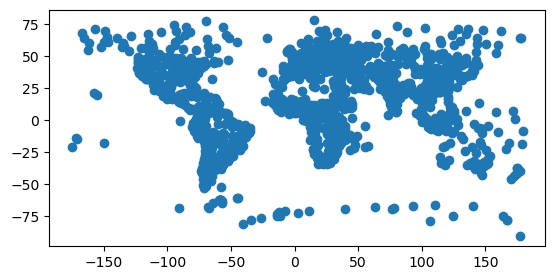

In [11]:
# Initial places plot
places.plot()

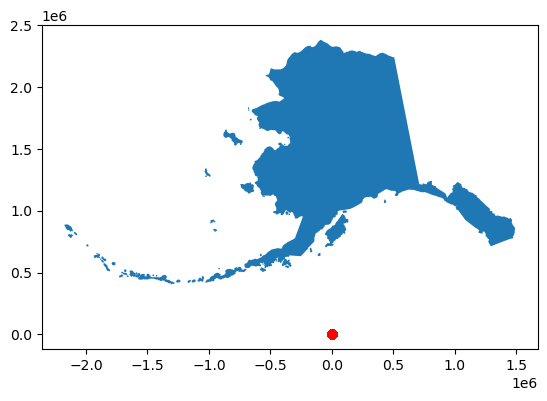

In [ ]:
# Trouble - crs do not match
fig, ax = plt.subplots()

alaska.plot(ax=ax)
places.plot(ax=ax, color='red')

plt.show()

In [ ]:
# Check crs
alaska.crs == places.crs

False

### Check-In

Reproject the places geo-dataframe into alaska’s CRS and verify the CRSs match using assert.

In [14]:
# Reproject to a new EPSG code (e.g., EPSG:3338 for Alaska or EPSG:32630)
places = places.to_crs(alaska.crs)

# Check crs
alaska.crs == places.crs

True

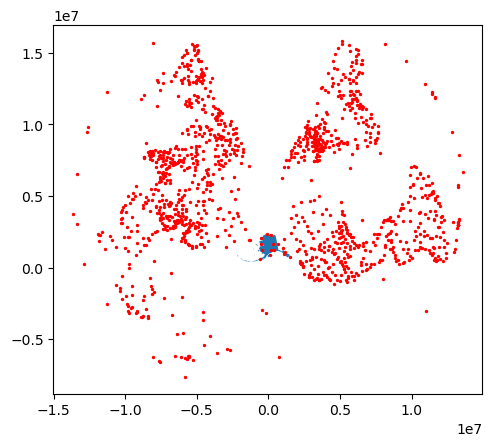

In [15]:
# Replot now that crs match

fig, ax = plt.subplots()

alaska.plot(ax=ax)
places.plot(ax=ax, color='red', markersize=2)

plt.show()

## Clipping

Clipping means using a polygon (or polygons) to keep only the parts of the geometries that fall inside them. Clipping a geopandas.GeoDataFrame is simple using the geopandas clip() function. The general syntax is:

```{python}
updated_geodf = geopandas.clip(geodf, mask)
```

where:

`updated_geodf` is the output of the function: the intersection of the geometries in geodf with mask

`geodf` is the geopandas.GeoDataFrame we want to clip

`mask` is a geopandas.GeoDataFrame with the polygon(s) we want to use for clipping (we will see later that it can also be a bounding box). This mask must be in the same CRS as geodf!

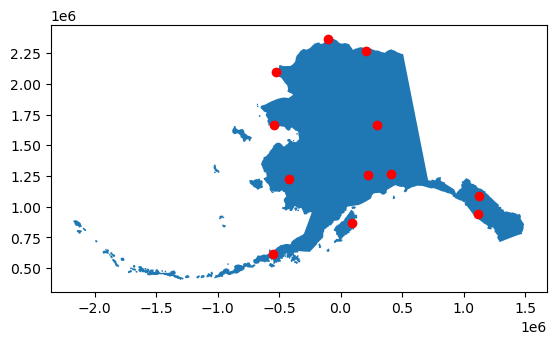

In [16]:
# Clip populated places to the Alaska multipolygon
ak_places = gpd.clip(places, alaska)

fig, ax = plt.subplots()
alaska.plot(ax=ax)
ak_places.plot(ax=ax, color='red')
plt.show()

## Prepare roads

In [17]:
# Check crs
print(roads.crs)

# Print df head
roads.head(3)

EPSG:4326


,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
0,8,Road,Secondary Highway,CAN,None,"Version 1.5: Changed alignment, a few adds in ...",None,None,None,None,0,3,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,314705,North America,0,None,7.1,9.6,"LINESTRING (-133.32533 62.21571, -133.31664 62..."
1,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",83,None,None,None,0,164,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,108105,North America,0,Federal,7.0,8.6,"LINESTRING (-100.50543 42.80753, -100.53495 42..."
2,7,Road,Secondary Highway,USA,None,"Version 1.5: Changed alignment, a few adds in ...",840,None,None,None,0,98,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,0,North America,0,U/C,7.0,9.5,"LINESTRING (-87.27432 36.02439, -87.22916 35.9..."


In [28]:
# Explore roads
roads['type'].value_counts()

type
Unknown              25766
Road                 11531
Major Highway         9752
Secondary Highway     9025
Ferry Route            309
Beltway                168
Track                   39
Bypass                   5
Ferry, seasonal          5
Name: count, dtype: int64

<Axes: >

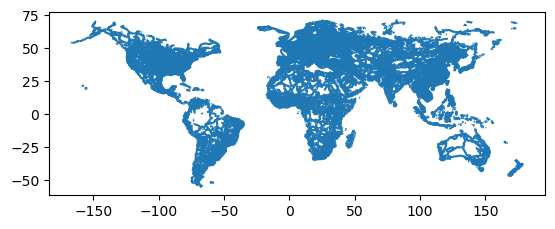

In [18]:
# Initial roads plot
roads.plot()

<Axes: >

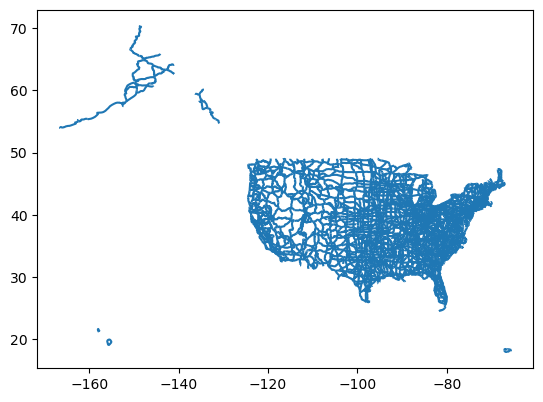

In [19]:
# Subset roads to US only
usa_roads = roads[roads['sov_a3'] == 'USA']
usa_roads.plot()

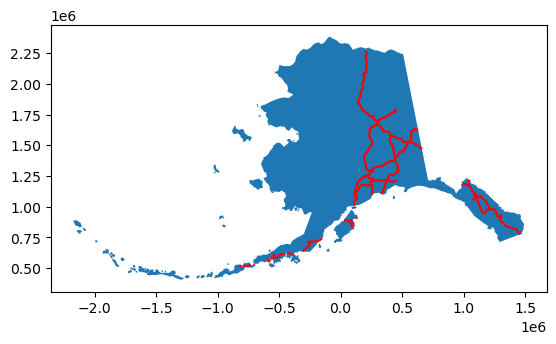

In [ ]:
# Clip usa_roads to alaska geometry and reproject crs
ak_roads = gpd.clip(usa_roads.to_crs(alaska.crs), alaska)

# Plot alaska and roads
fig, ax = plt.subplots()
alaska.plot(ax=ax)
ak_roads.plot(ax=ax, color='red')
plt.show()

## Clipping with a bounding box

Bounding box (bbox) defined by minx, miny, maxx, maxy

In [21]:
# Find bbox of alaska
alaska.total_bounds

array([-2175729.73162241,   404545.10791528,  1493082.30904445,
        2383808.43520815])

In [22]:
# Clip to alaska roads with crs match and bbox (one step)
ak_complete_roads = gpd.clip(usa_roads.to_crs(alaska.crs), alaska.total_bounds)

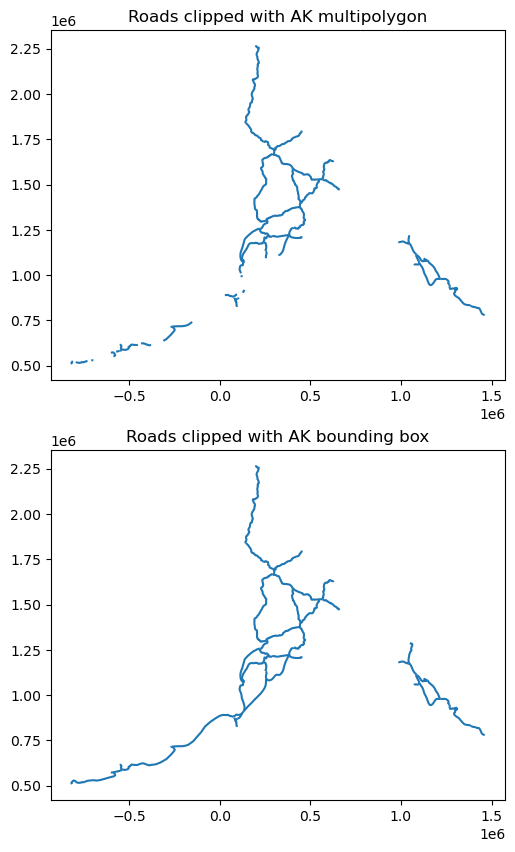

In [ ]:
# Plot clipped alaska versions

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10,10))

# Multipolygon
ak_roads.plot(ax=ax1)
ax1.set_title('Roads clipped with AK multipolygon')

# Bbox
ak_complete_roads.plot(ax=ax2)
ax2.set_title('Roads clipped with AK bounding box')

plt.show()

## Measuring lengths

To understand the difference between the two clips, we will compare the lengths of their roads. Geo-dataframes have a length attribute that calculates the length of each line from its geometry, in the units of the CRS. Let’s try it on one road in Alaska, the road with index 1138:

In [ ]:
# Find length of road w/ index 1138 - triggers warning since geo is geographic crs
usa_roads.loc[[1138]].length

/var/folders/27/3jvf7rts3gjbq79rmz16ywp40000gq/T/ipykernel_49143/693157629.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  usa_roads.loc[[1138]].length


1138    4.051932
dtype: float64

In [25]:
# Reproject to the 2D projected Alaska CRS and convert meters to kilometers
usa_roads.loc[[1138]].to_crs('epsg:3338').length / 1000

1138    287.473411
dtype: float64

## How does clipping affect the data?

In [26]:
# Compare number of roads btwn clip versions
print('Number of roads (polygon clip):', len(ak_roads))
print('Number of roads (bbox clip):   ', len(ak_complete_roads))

# Compare total length of all roads btwn clip versions
# Divide by 1000 to convert meters to kilometers
print('Total length in km (polygon clip):', round(ak_roads.length.sum() / 1000))
print('Total length in km (bbox clip):   ', round(ak_complete_roads.length.sum() / 1000))

Number of roads (polygon clip): 56
Number of roads (bbox clip):    56
Total length in km (polygon clip): 6069
Total length in km (bbox clip):    7111


Both geo-dataframes have the same number of rows: clipping to the polygons did not drop any road. Instead, gpd.clip() cut the roads that cross the coastline, so the polygon clip has about 1,000 fewer kilometers of roads. The difference is in the geometries, not in the number of rows.

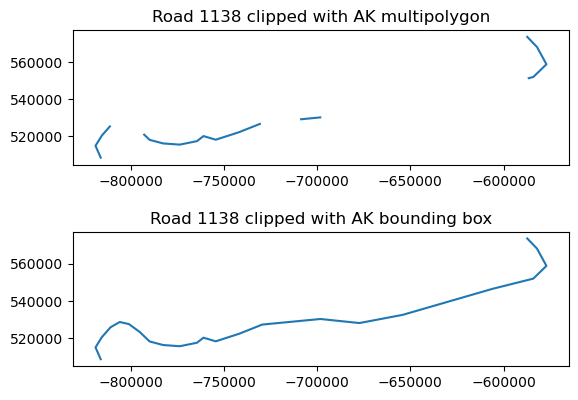

In [27]:
# Zoom in on ferry route in the eastern Aleutian Islands (index 1138)

fig, (ax1, ax2) = plt.subplots(2, 1)

ak_roads.loc[[1138]].plot(ax=ax1)
ax1.set_title('Road 1138 clipped with AK multipolygon')

ak_complete_roads.loc[[1138]].plot(ax=ax2)
ax2.set_title('Road 1138 clipped with AK bounding box')

plt.show()

The polygon clip kept only the pieces of the ferry route that cross the islands and removed the parts over water. The bounding box clip kept the whole route, because all of it is inside Alaska’s bounding box. Let’s compare the length and geometry type of road 1138 in each geo-dataframe:

In [29]:
# Print length of road 1138 in each clip version
print('Length in km (polygon clip):', round(ak_roads.length[1138] / 1000, 1))
print('Length in km (bbox clip):   ', round(ak_complete_roads.length[1138] / 1000, 1))

# Print geo type road 1138 in each clip version
print('Geometry type (polygon clip):', ak_roads.geom_type[1138])
print('Geometry type (bbox clip):   ', ak_complete_roads.geom_type[1138])

Length in km (polygon clip): 131.6
Length in km (bbox clip):    287.5
Geometry type (polygon clip): MultiLineString
Geometry type (bbox clip):    LineString


In [31]:
# Only the geo column id different - other columns unchanged
ak_roads.loc[[1138]]
ak_complete_roads.loc[[1138]]

,scalerank,featurecla,type,sov_a3,note,edited,name,namealt,namealtt,routeraw,question,length_km,toll,ne_part,label,label2,local,localtype,localalt,labelrank,ignore,add,rwdb_rd_id,orig_fid,prefix,uident,continent,expressway,level,min_zoom,min_label,geometry
1138,7,Ferry,Ferry Route,USA,None,New in version 2.0.0,None,None,None,None,0,435,0,ne_1d4_original,None,None,None,None,None,0,0,0,0,0,None,4305,North America,0,Ferry,7.0,9.5,"LINESTRING (-587641.011 573877.088, -582019.27..."


This means attributes that depend on the geometry, like the length_km column in our roads data, still describe the original, uncut features. If we need them for the clipped data, we have to recalculate them from the new geometries. Heads up: length_km was stored by Natural Earth and doesn’t always match the geometries even before clipping (for road 1138 it says 435 km, but we measured about 287 km), so it’s good practice to check stored attributes against the data.

## Plot and Exercises

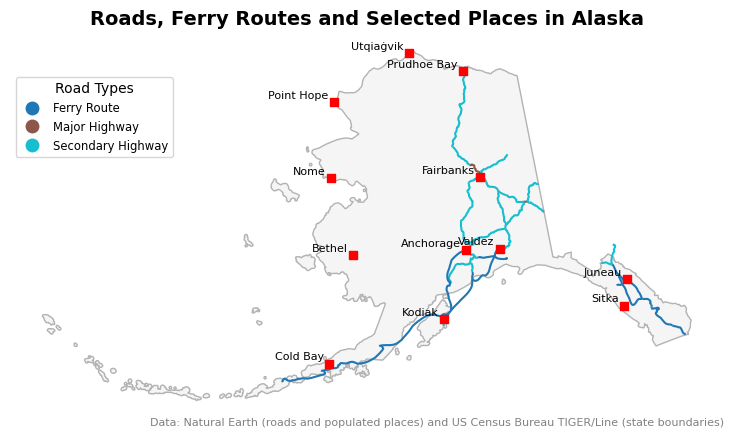

In [35]:
# Assemble entire alaska, roads, places plot

fig, ax = plt.subplots(figsize=(11,5))
ax.axis('off')

alaska.plot(ax=ax, color='whitesmoke', edgecolor='0.7')

ak_complete_roads.plot(ax=ax, 
                       zorder=1,  # Specify layer plotting order
                       column='type', 
                       legend=True,
                       legend_kwds={'title': "Road Types", 
                                    'loc': 'upper left',
                                    'bbox_to_anchor':(0,0.9),
                                    'fontsize':'small'}
                                    )

ak_places.plot(ax=ax, 
               zorder=2,  # Specify layer plotting order
               color='red', 
               marker='s'  # Square marker
               )
# Add city names as text annotations
for x, y, name in zip(ak_places.geometry.x, ak_places.geometry.y, ak_places['name']):
    ax.text(x-30000, y+20000, name, fontsize=8, ha='right')

ax.set_title("Roads, Ferry Routes and Selected Places in Alaska", fontsize=14, fontweight='bold')

# Add data sources below the map
ax.annotate("Data: Natural Earth (roads and populated places) and US Census Bureau TIGER/Line (state boundaries)",
            xy=(1, 0), xycoords='axes fraction',  # Bottom-right corner of the axes
            ha='right', va='top', fontsize=8, color='gray')

plt.show()

### Exercise 1:

Notice the overlapping labels for Anchorage and Valdez.
Update the map so these labels do not overlap. One way to do it is using an if when iterating over the Alaska populated places. Remember that the map is in the EPSG:3338 CRS, whose units are meters, so the label offsets (like x-30000) are in meters too.

### Exercise 2:

Look closely at southeast Alaska. A short road goes past the Alaska border into Canada. Why is this road on our map of Alaska? How could you update the map so it only shows roads inside Alaska but still includes the ferry routes?